# 2. What does damage mean?

A passive frozen cell cannot initiate swaps but can be pushed. An immovable cell cannot be swapped at all. We compare these models using identical initial values and fixed cell identities. Successful recovery, a policy that is stuck, and a run hitting its budget are different outcomes.

In [1]:
%matplotlib inline
from pathlib import Path
import tempfile
import matplotlib.pyplot as plt
from cell_research.experiment import Config, run, replay
Path("outputs").mkdir(exist_ok=True)
output = Path(tempfile.mkdtemp(prefix="damage-", dir="outputs"))

## The smallest regression case

Freeze identity 0, whose initial value is 2. The passive model can sort; the immovable model cannot. Frozen identities follow their cells when those cells are pushed.

In [2]:
for mode in ("passive", "immovable"):
    result = run(Config([2, 1], frozen_ids=[0], frozen_mode=mode))
    result.save(output / mode)
    print(mode, result.termination, result.final_values, "final IDs:", result.final_order)
    replay(output / mode)

passive sorted [1, 2] final IDs: [1, 0]
immovable stuck [2, 1] final IDs: [0, 1]


## Paired experiments, including failures

For each of 20 trials, all three conditions share an initial permutation of 12 values and a policy seed. The two damaged conditions share exactly two distinct frozen identities. Random scheduling includes frozen IDs, keeping the same activation-stream prefix across paired runs. Passive frozen cells can still block one another; recovery is not guaranteed.

The bars summarize complete sorting. Intervals are marginal 95% Wilson intervals, not a statistical test of the paired differences. The CSV files retain stuck and limited outcomes.

{'condition': 'intact', 'trials': 20, 'sorted': 20, 'stuck': 0, 'limited': 0, 'success_rate': 1.0, 'ci95_low': 0.8388748419471806, 'ci95_high': 1.0}
{'condition': 'passive', 'trials': 20, 'sorted': 7, 'stuck': 13, 'limited': 0, 'success_rate': 0.35, 'ci95_low': 0.18119182410108206, 'ci95_high': 0.5671457233147638}
{'condition': 'immovable', 'trials': 20, 'sorted': 0, 'stuck': 20, 'limited': 0, 'success_rate': 0.0, 'ci95_low': 0.0, 'ci95_high': 0.16112515805281938}


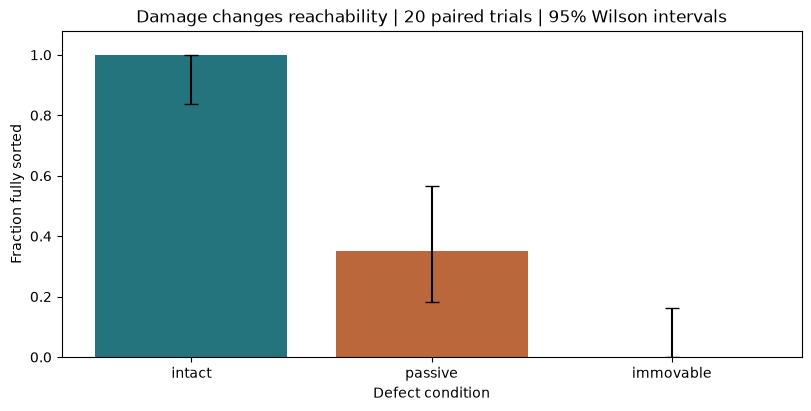

In [3]:
from cell_research.studies import damage_study
study = damage_study(output / "paired", trials=20, n=12, seed=17)
for row in study["summary"]:
    print(row)
plt.show()

## Compare execution schedules

The same cell policies run under seeded random, round-robin, and OS-thread scheduling. A threaded seed does not determine the order of activations. Its recorded order can still be replayed. This table illustrates individual runs, not a statistical comparison of schedulers.

In [4]:
for scheduler in ("random", "round_robin", "threaded"):
    config = Config([6, 2, 5, 1, 4, 3], seed=8, frozen_ids=[2], scheduler=scheduler)
    result = run(config)
    result.save(output / scheduler)
    assert replay(output / scheduler).summary() == result.summary()
    print(scheduler, result.termination, "activations:", len(result.events), "swaps:", result.summary()["swaps"])
print("Raw recordings and summaries:", output)

random sorted activations: 66 swaps: 10
round_robin sorted activations: 47 swaps: 10
threaded sorted activations: 3391 swaps: 10
Raw recordings and summaries: /Users/mhough/Workspace/cell_research/outputs/damage-p95rjgsf


## Explore

Repeat with one versus two frozen cells, larger arrays, or another sorting rule. Selection can swap nonadjacent cells across an immovable barrier. Insertion explicitly resets its prefix check at frozen cells. These implementation details belong in explanations of recovery.

Ask whether the target order is unreachable under the permitted swaps before interpreting failure as low competence. Never silently discard step-limited trials.

Sources: [sorting study](https://arxiv.org/abs/2401.05375), [fork methods](../docs/methods.md).